# Monsoon convection plots

Functions in `plotter.jl` (docstrings there: `?plot_time_height`). Edits to `plotter.jl` take effect without restarting, through Revise. On the cluster, write PNGs instead:
`julia --project=plots -e 'include("plotter.jl"); save_plots("run/ekamsat-ctl0")'`

In [1]:
cd("/ceoas/deszoeks/projects/monsoon-breeze/plots")
using Pkg; Pkg.activate(".")
using Revise
includet("plotter.jl")

rundir = joinpath("../run", "ekamsat-ctl0")

  Activating project at `/ceoas/deszoeks/projects/monsoon-breeze/plots`


"../run/ekamsat-ctl0"

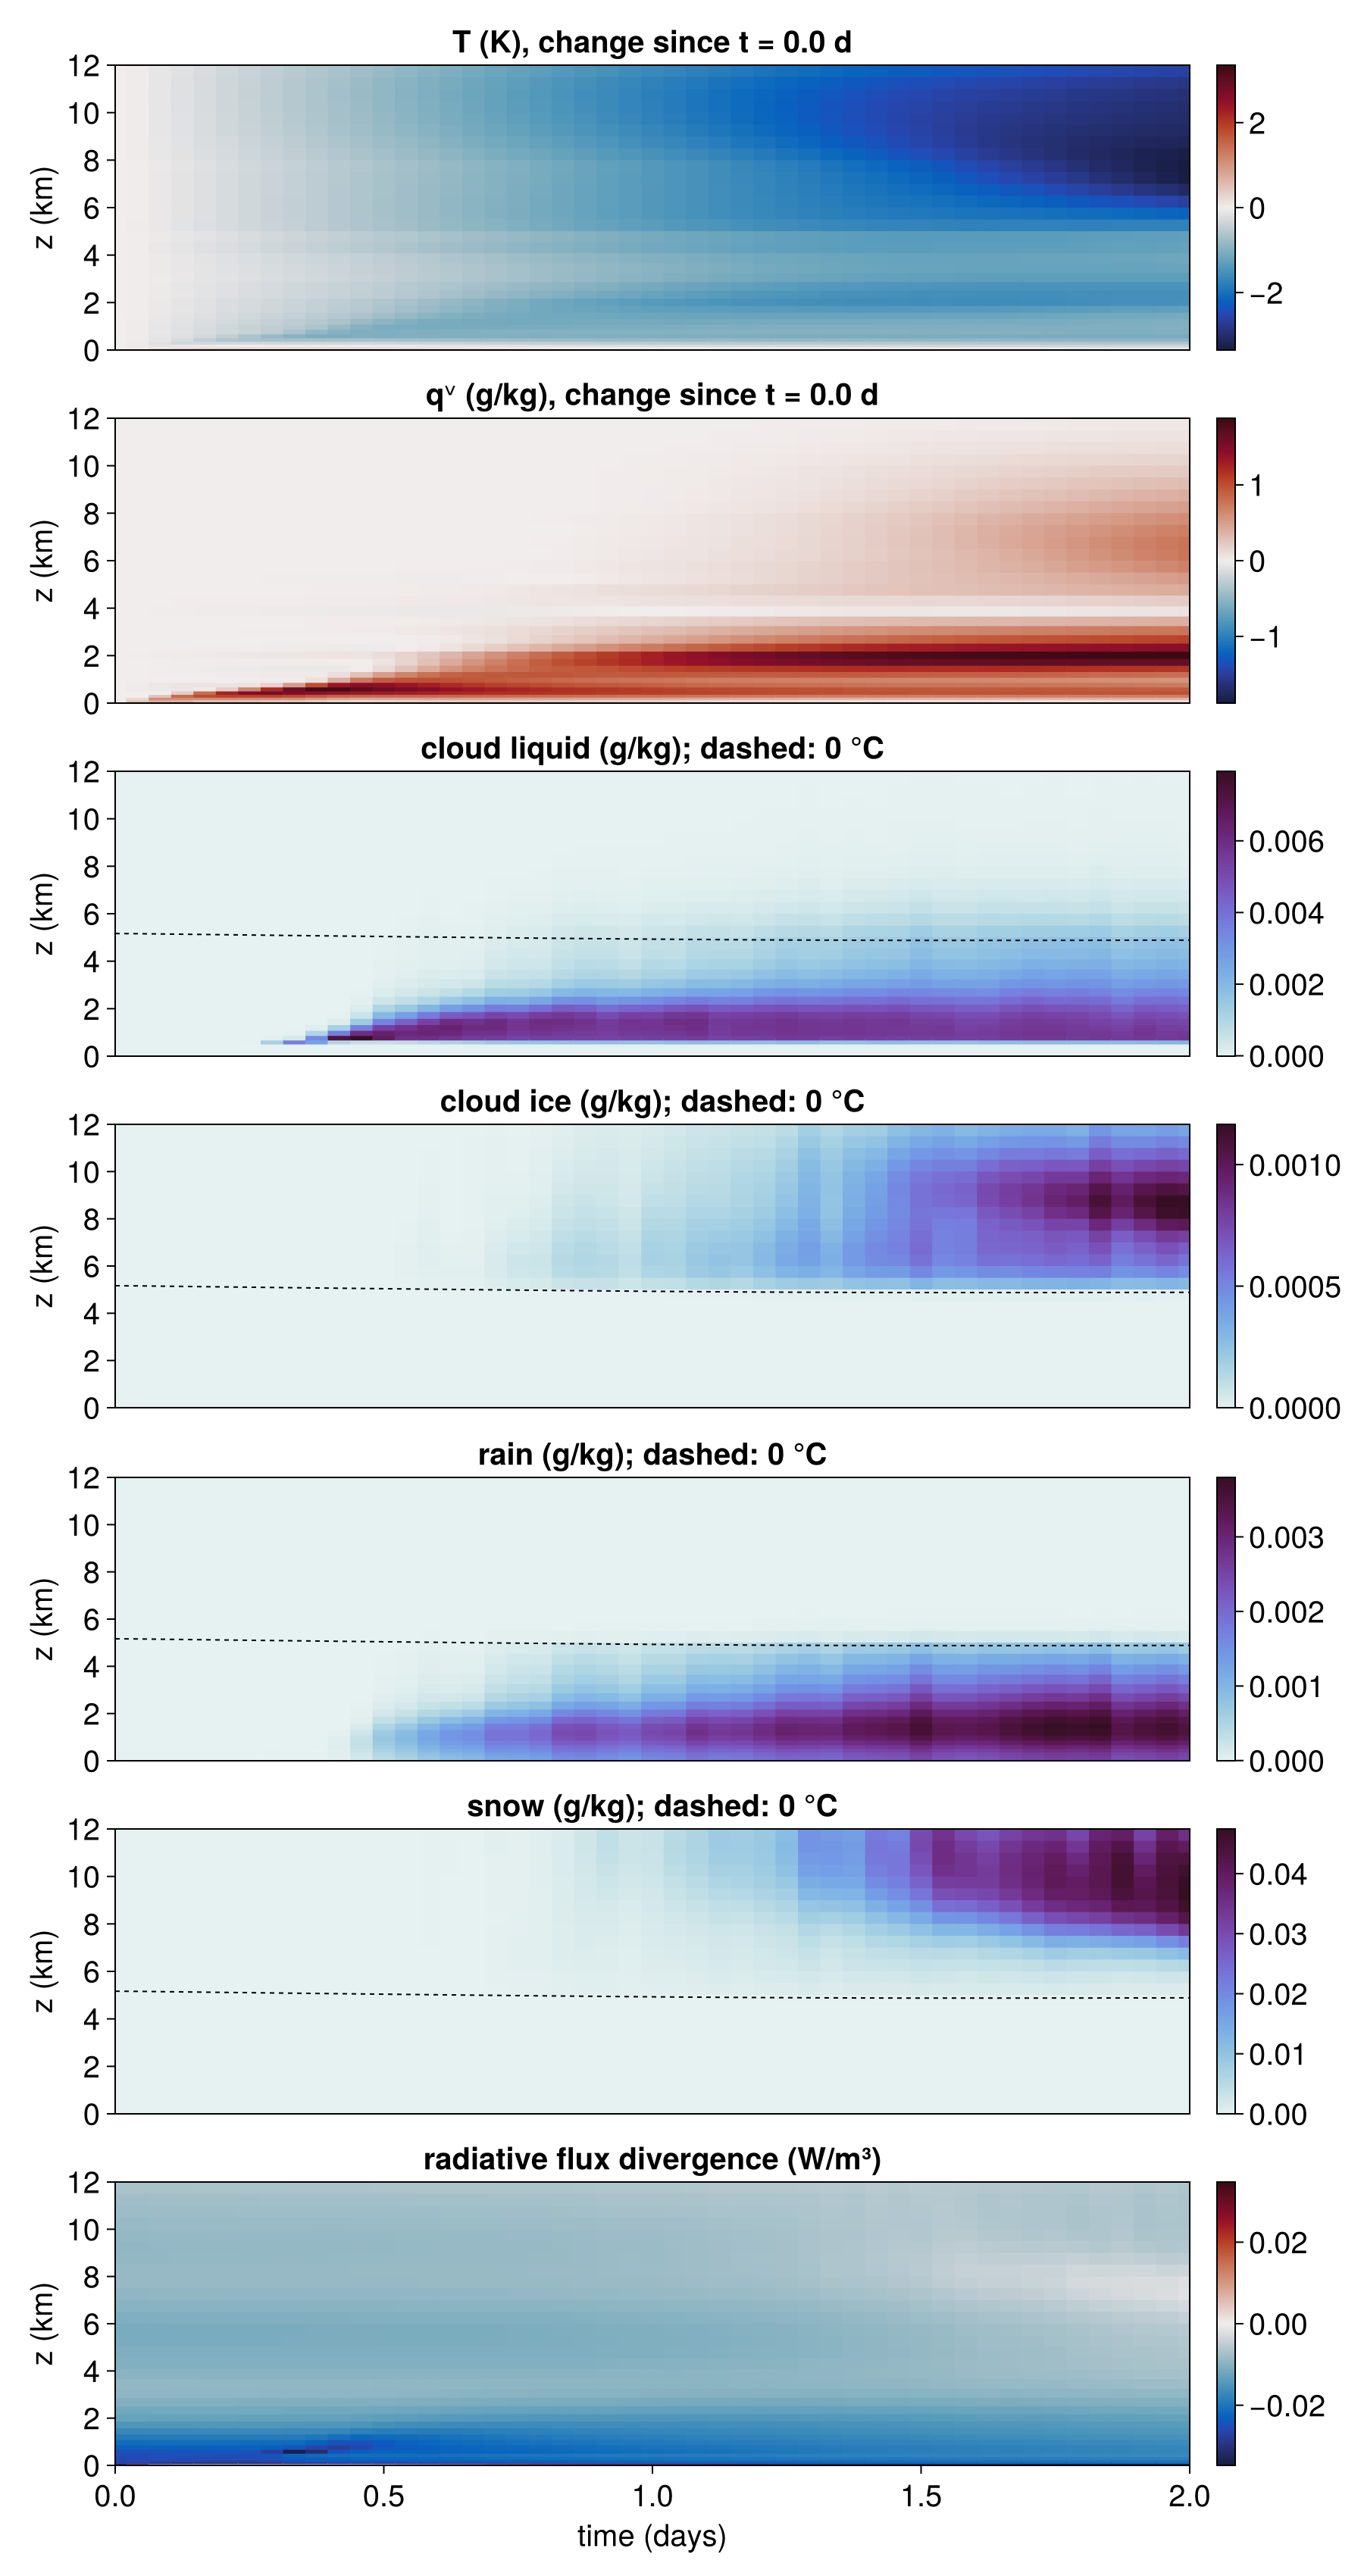

In [2]:
fig = plot_time_height(rundir; zmax = 12_000)

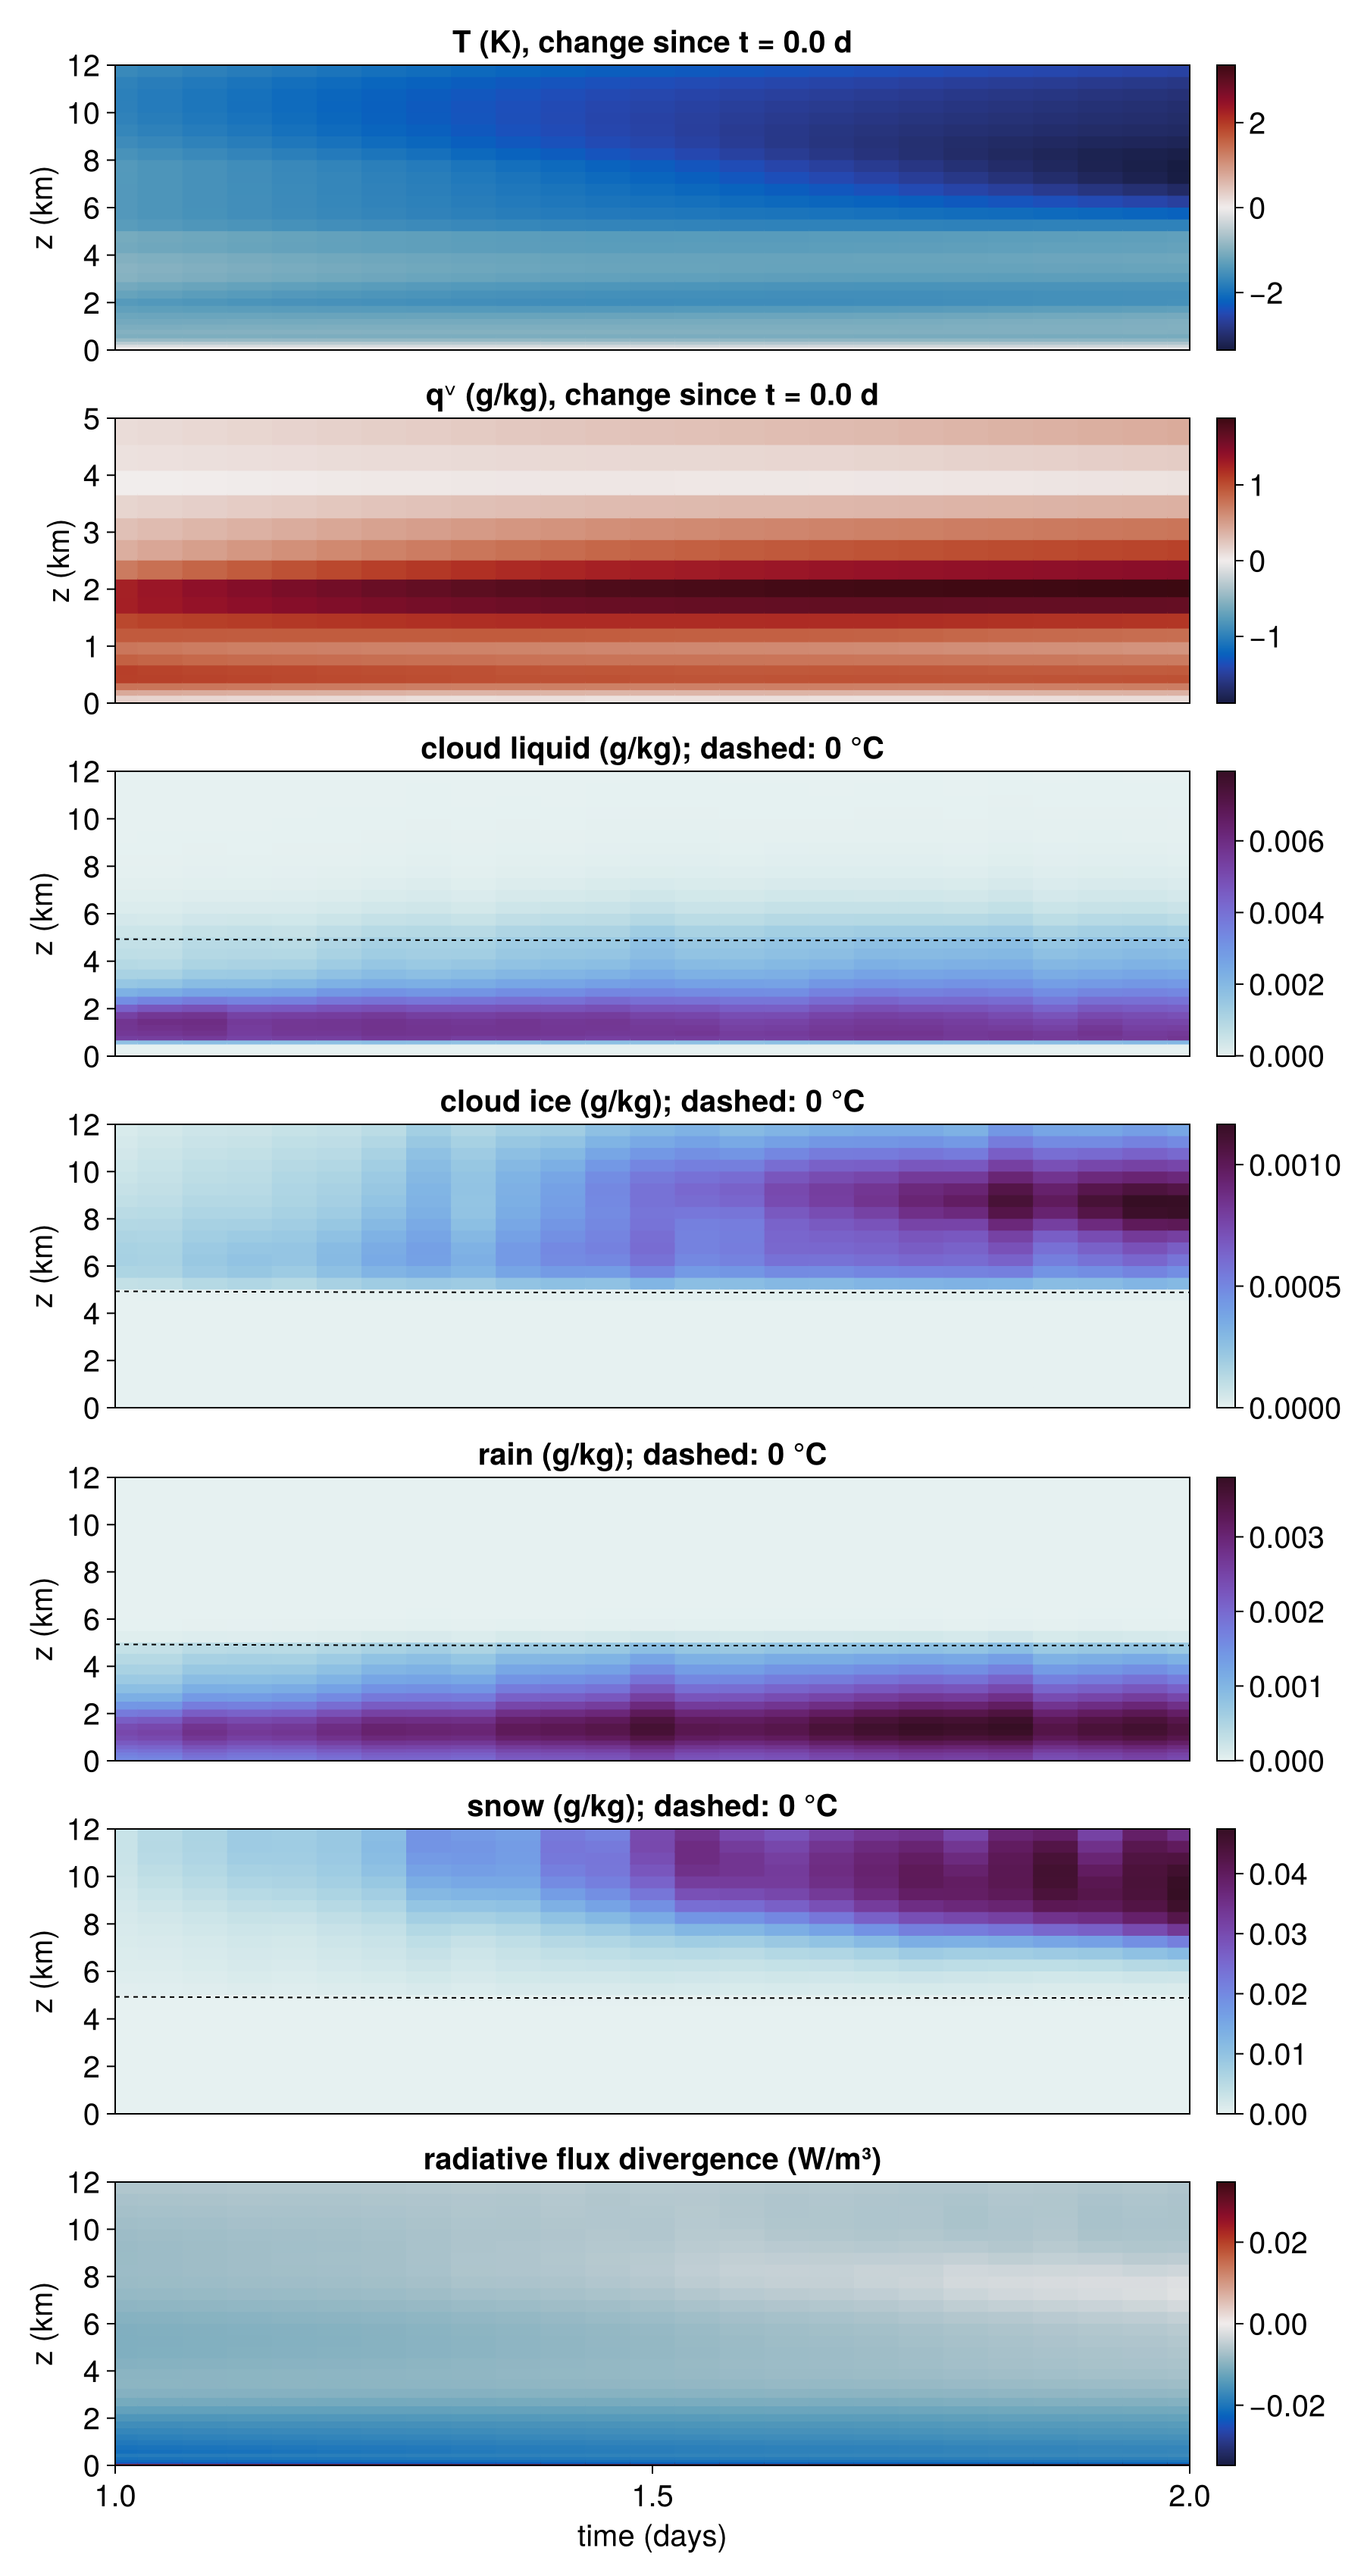

In [3]:
# Zoom: get a plotted axis (panel 2, qᵛ) and set its limits, then show the figure again.
# Time–height panels share the time axis, so xlims! zooms them all.
ax = plot_axes(fig)[2]
xlims!(ax, 1, 2)      # days
ylims!(ax, 0, 5)      # km
fig

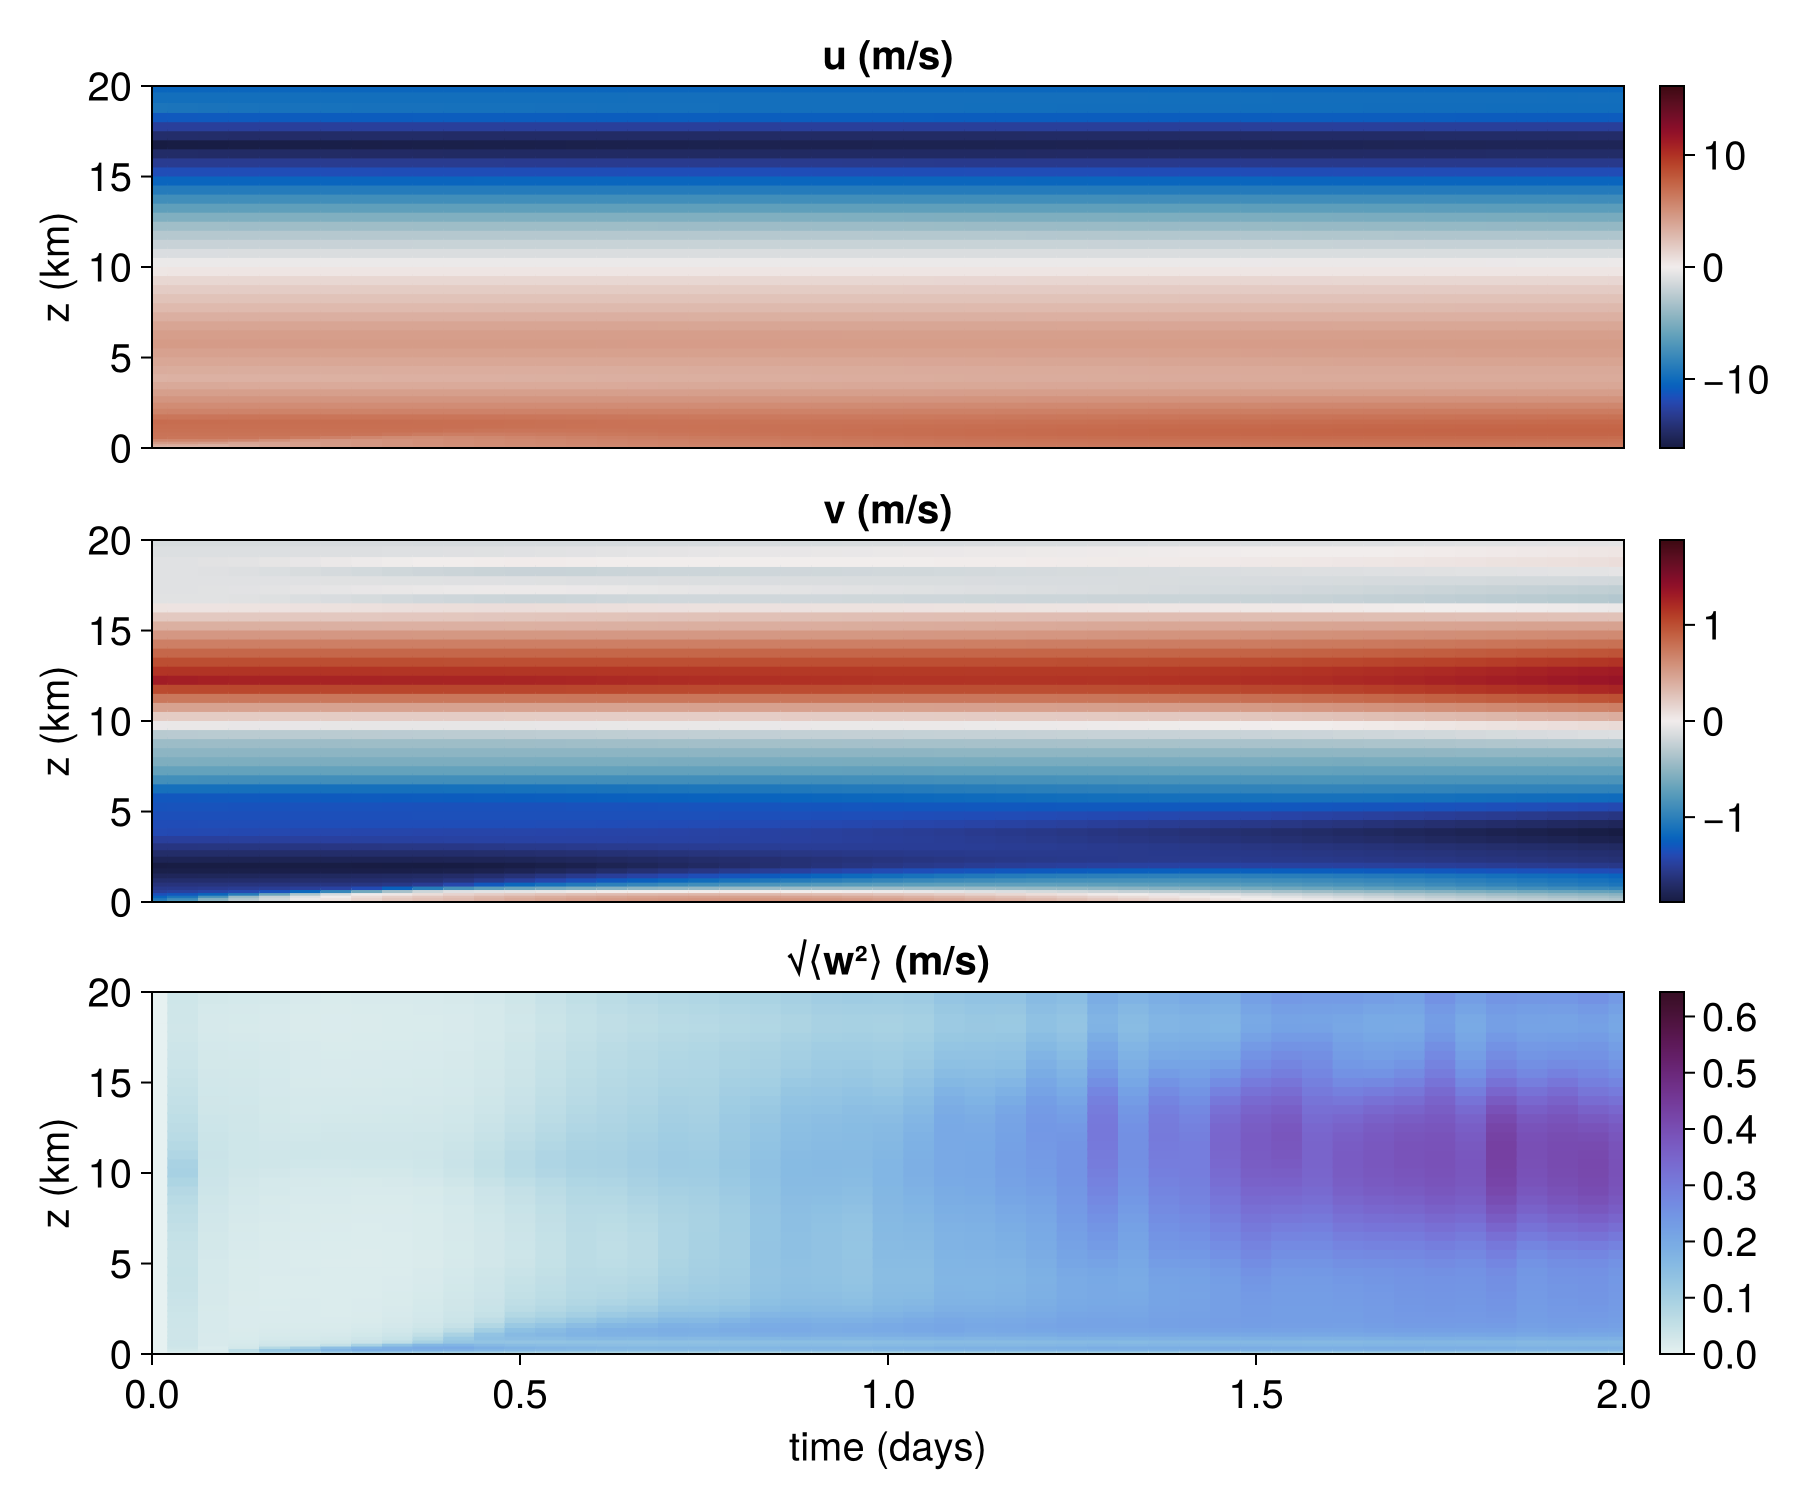

In [4]:
fig_wind = plot_wind_time_height(rundir)

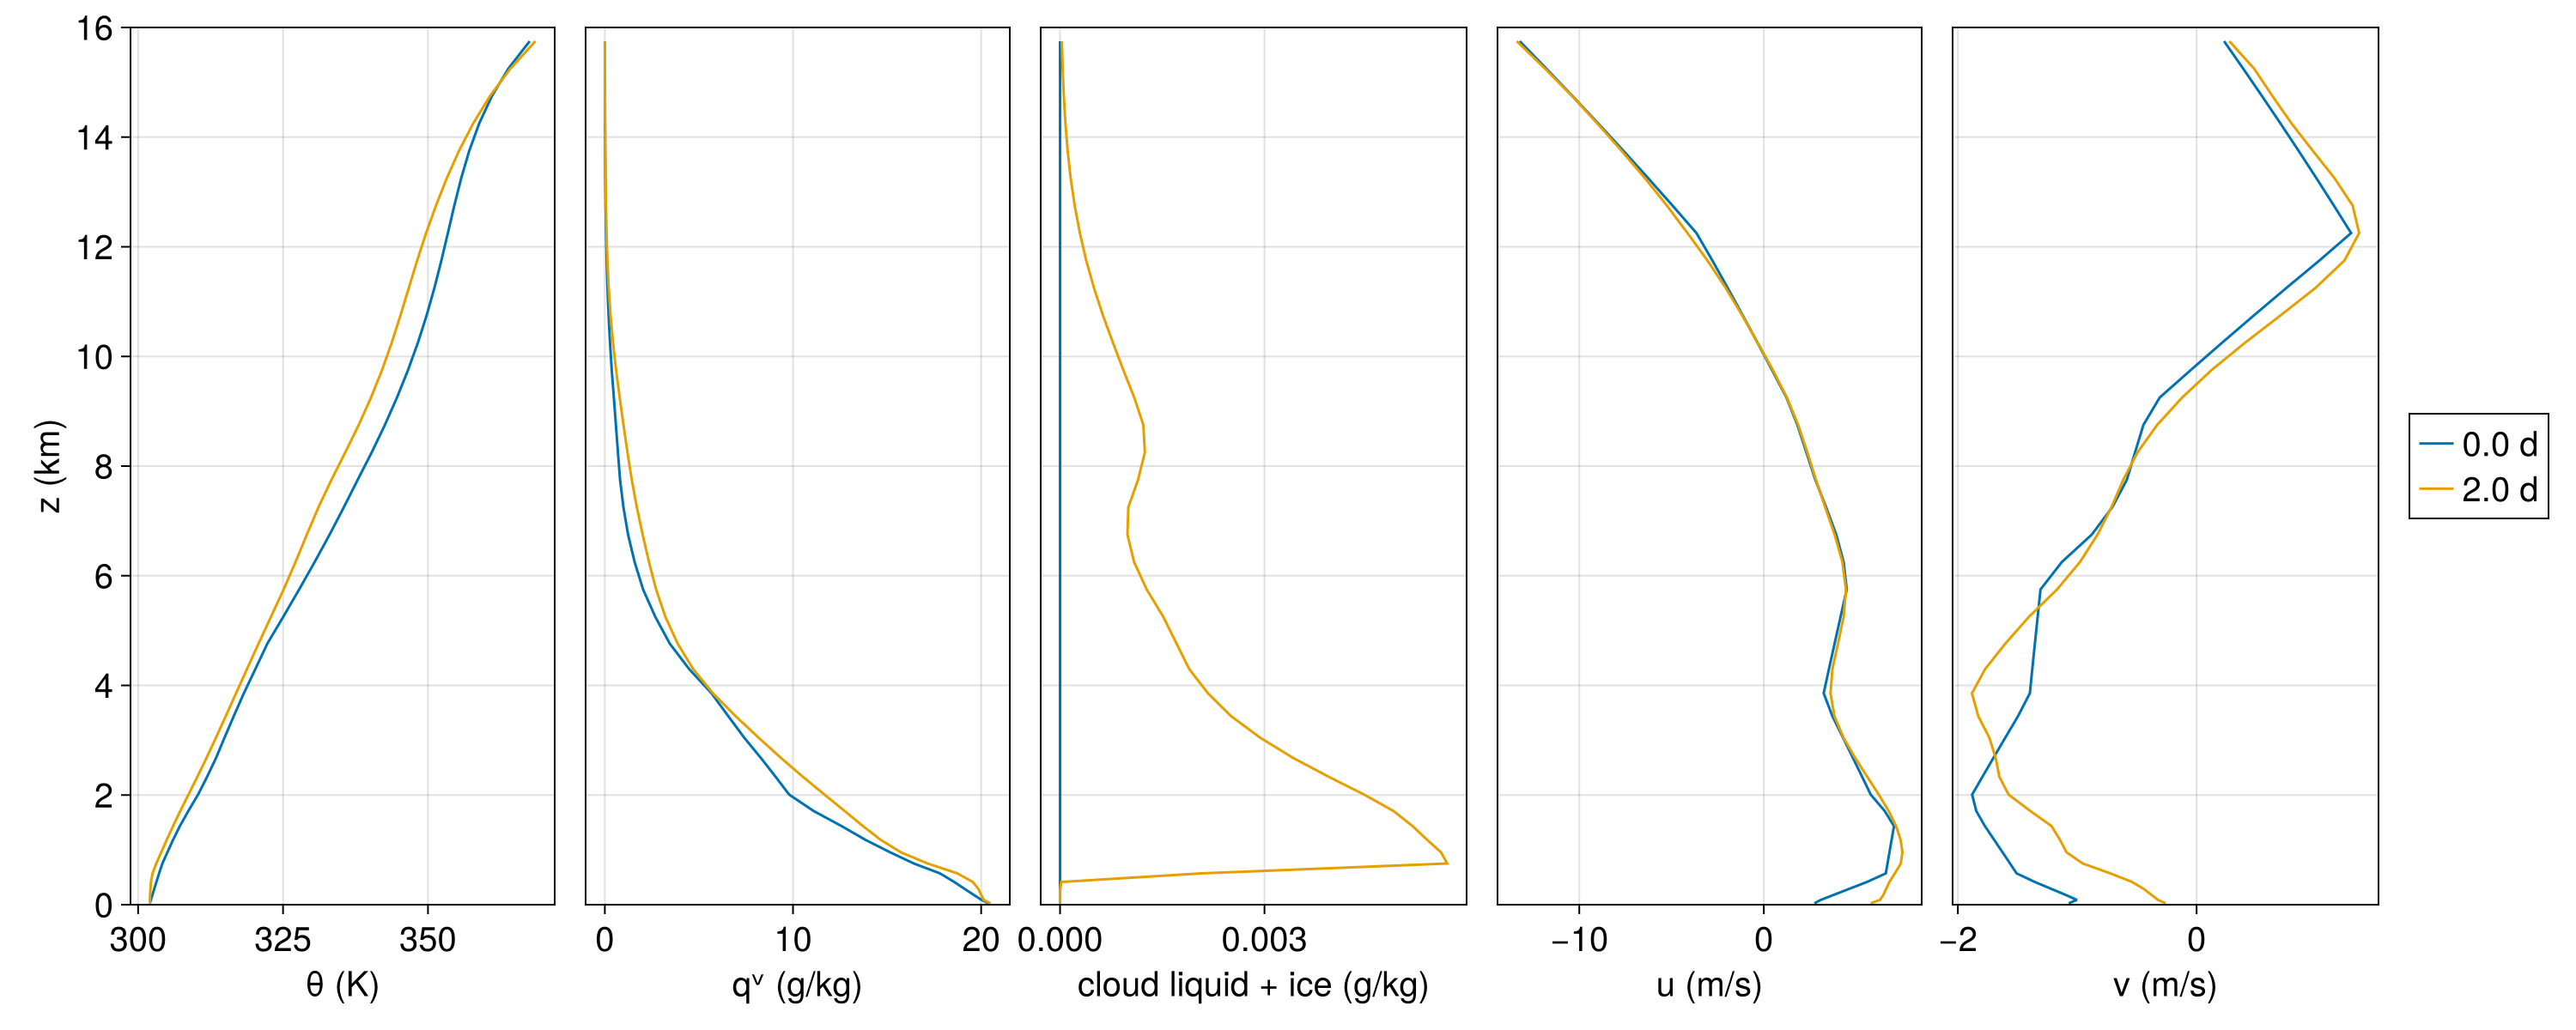

In [5]:
fig_profiles = plot_profiles(rundir; ns = (first, last))

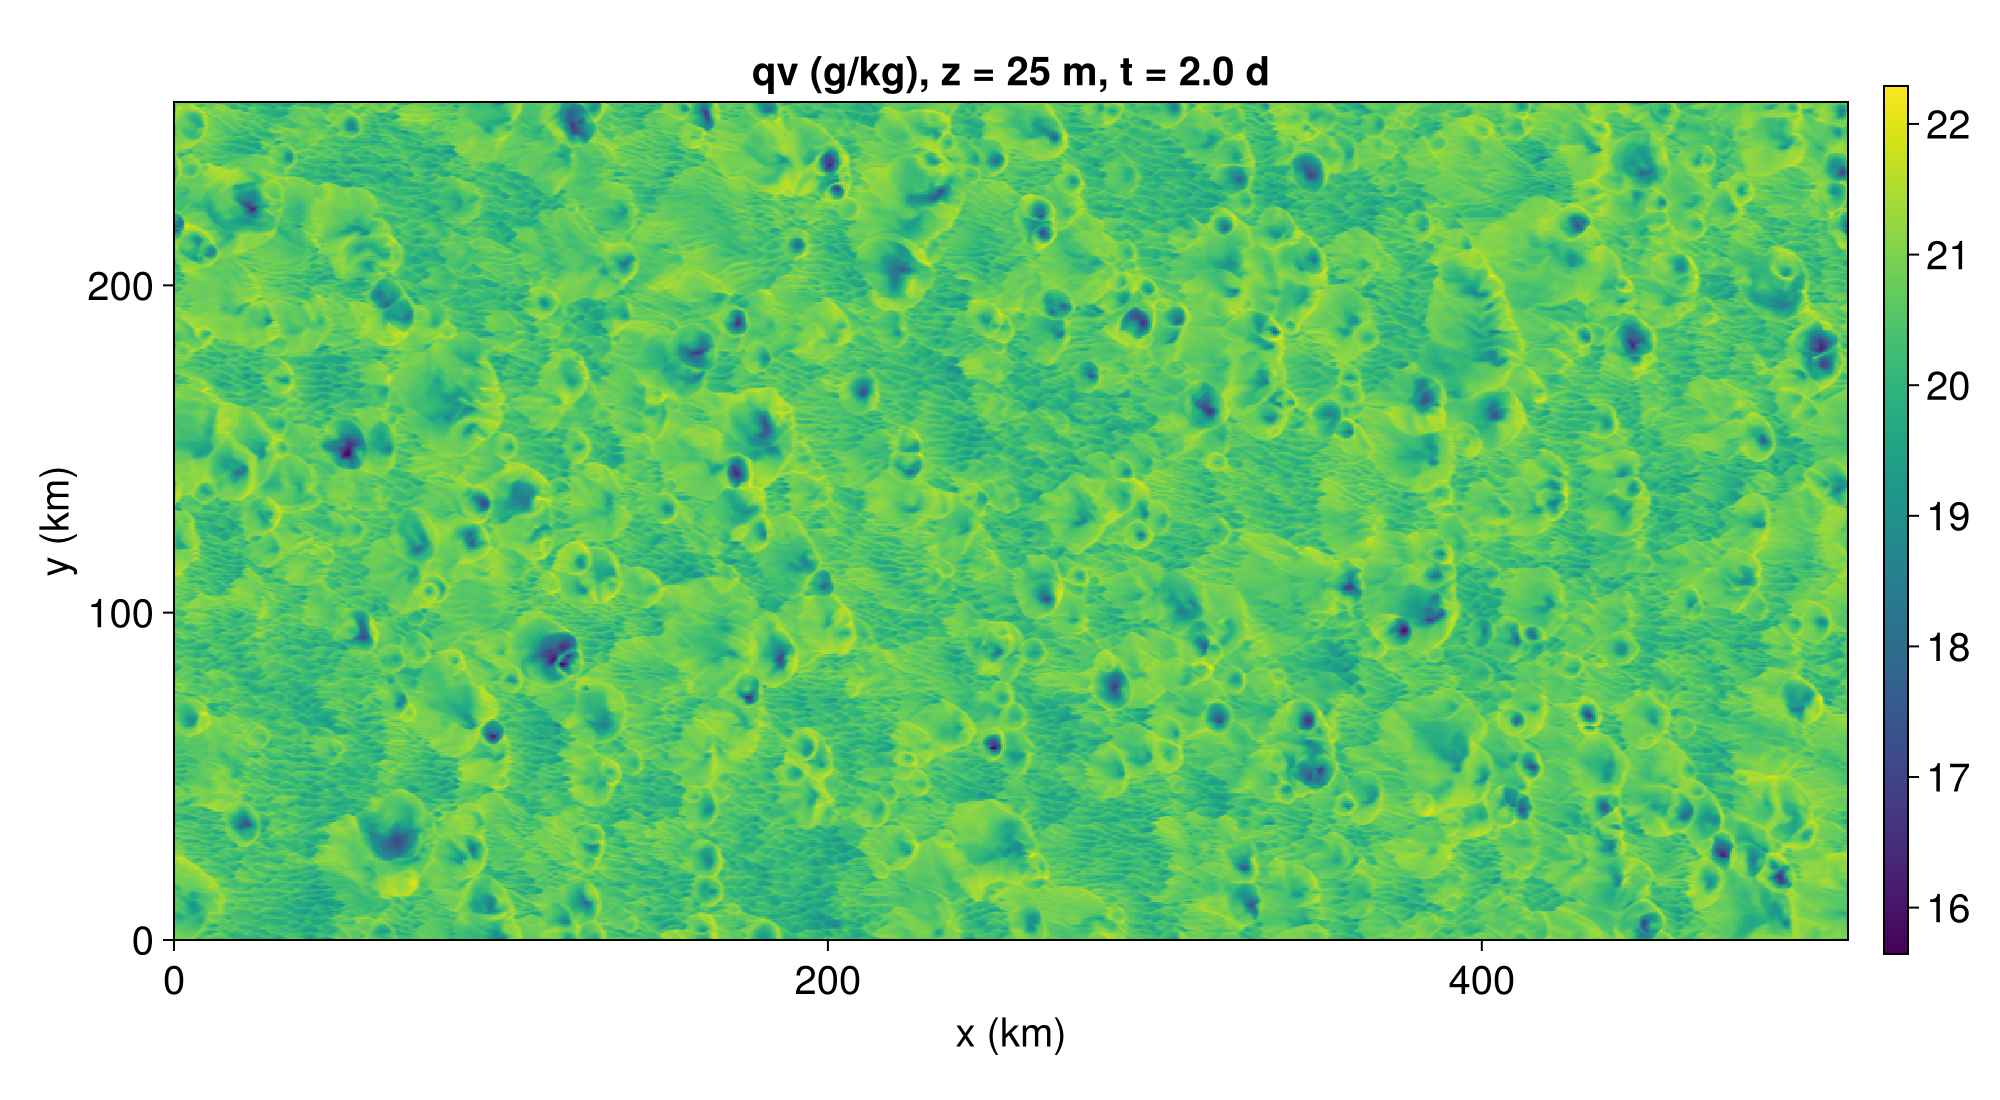

In [6]:
plot_xy(rundir, "qv"; n = last)            # lowest level, hourly (_surface.nc)

In [7]:
snapshot_times(rundir)                     # days of the 3D snapshots (_fields.nc)

3-element Vector{Float64}:
 0.0
 1.0
 2.0

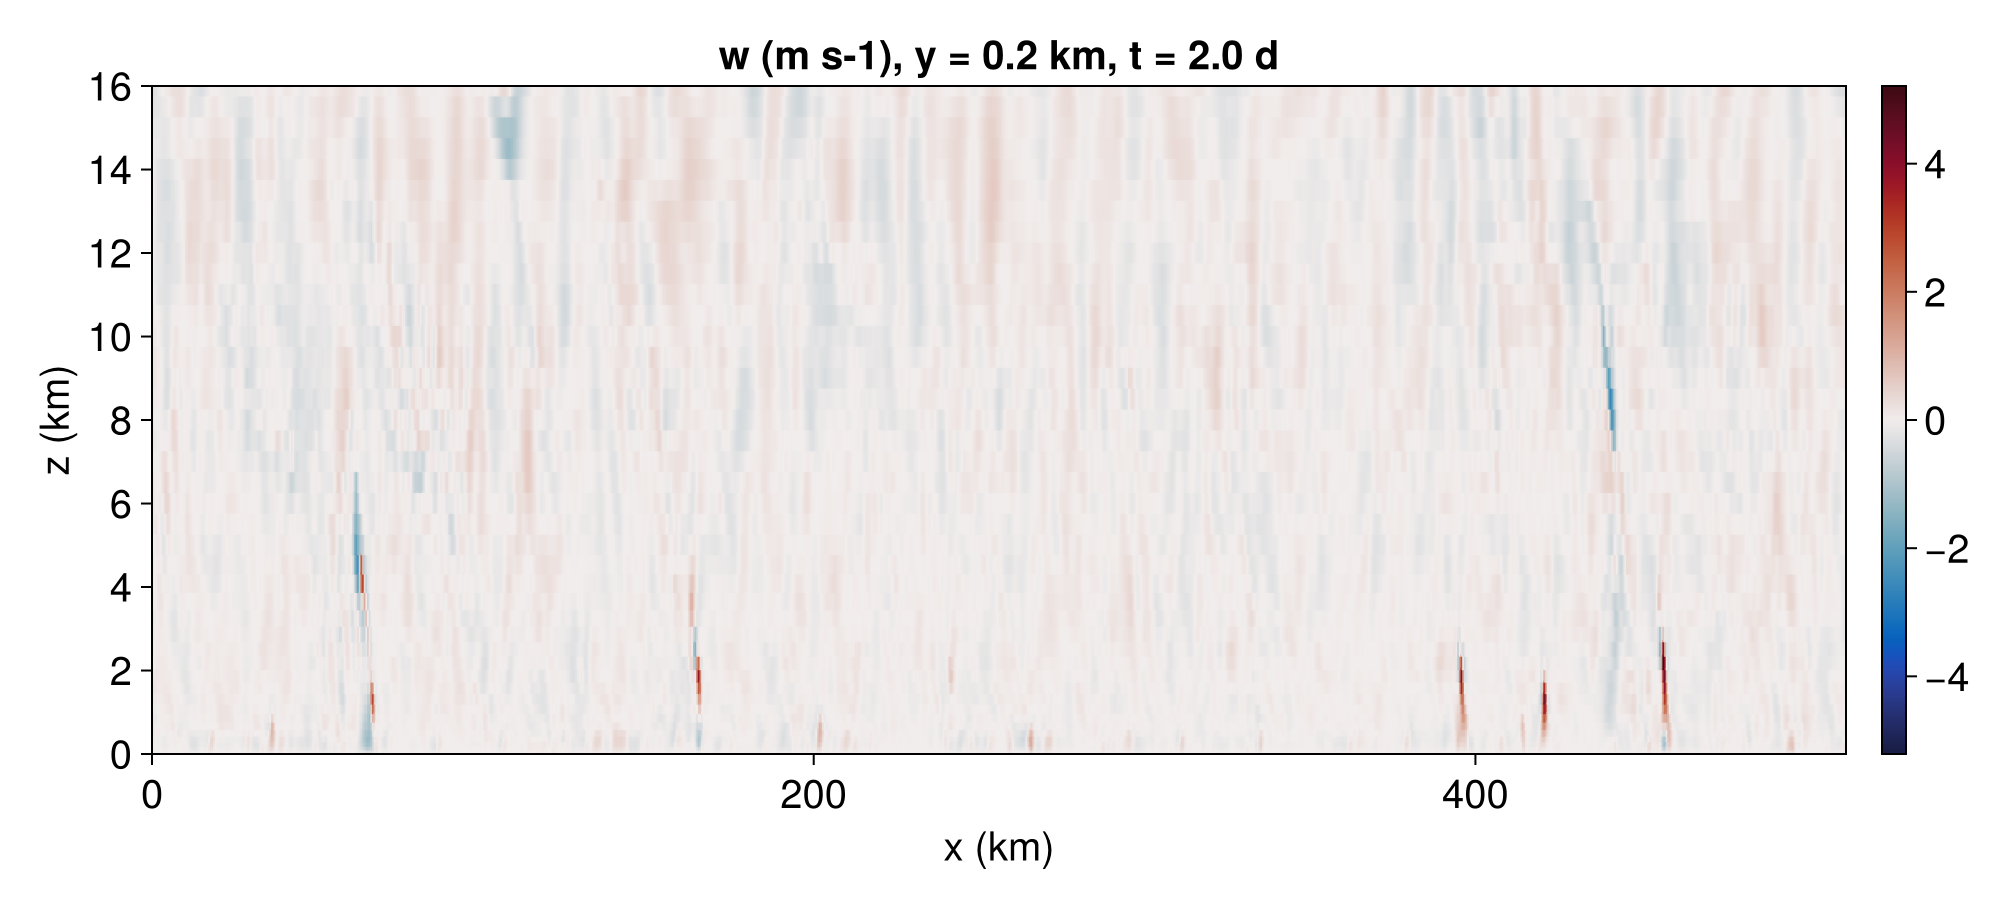

In [8]:
fig_xz = plot_xz(rundir, "w"; j = 1, n = last)

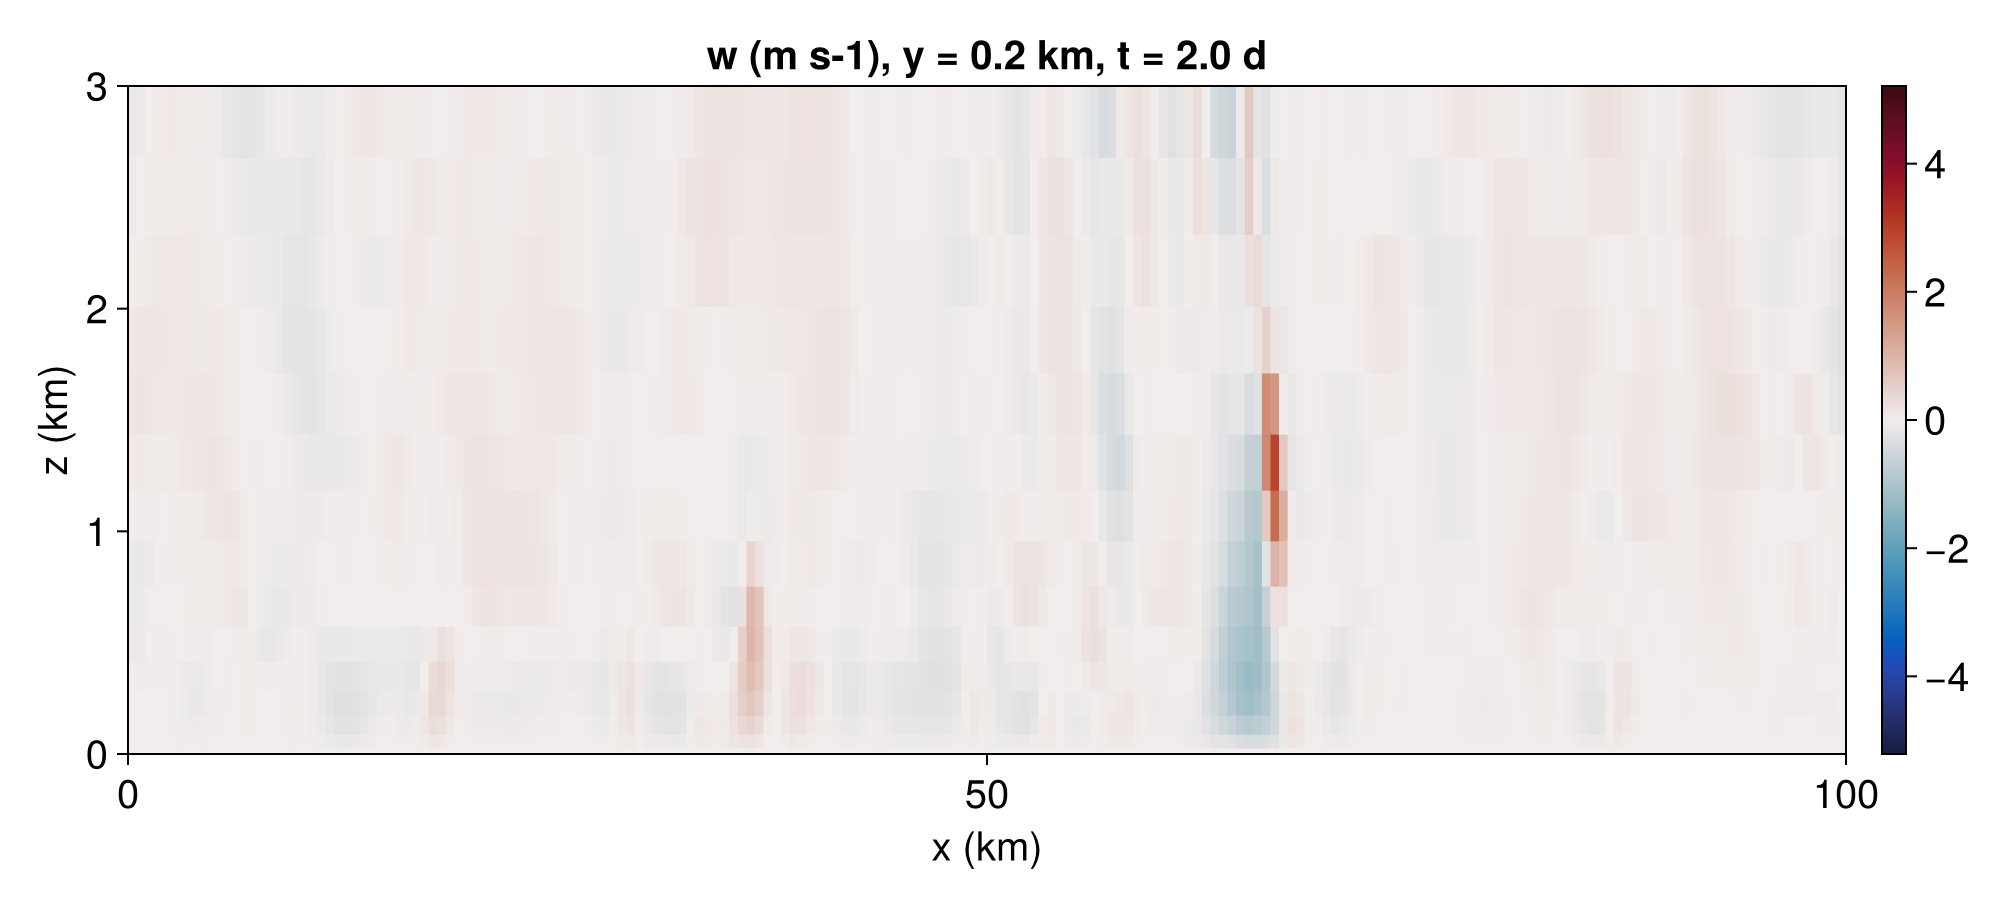

In [9]:
# Zoom the x–z section to the lowest 3 km and the first 100 km
ax = plot_axes(fig_xz)[1]
limits!(ax, 0, 100, 0, 3)     # x (km), z (km)
fig_xz

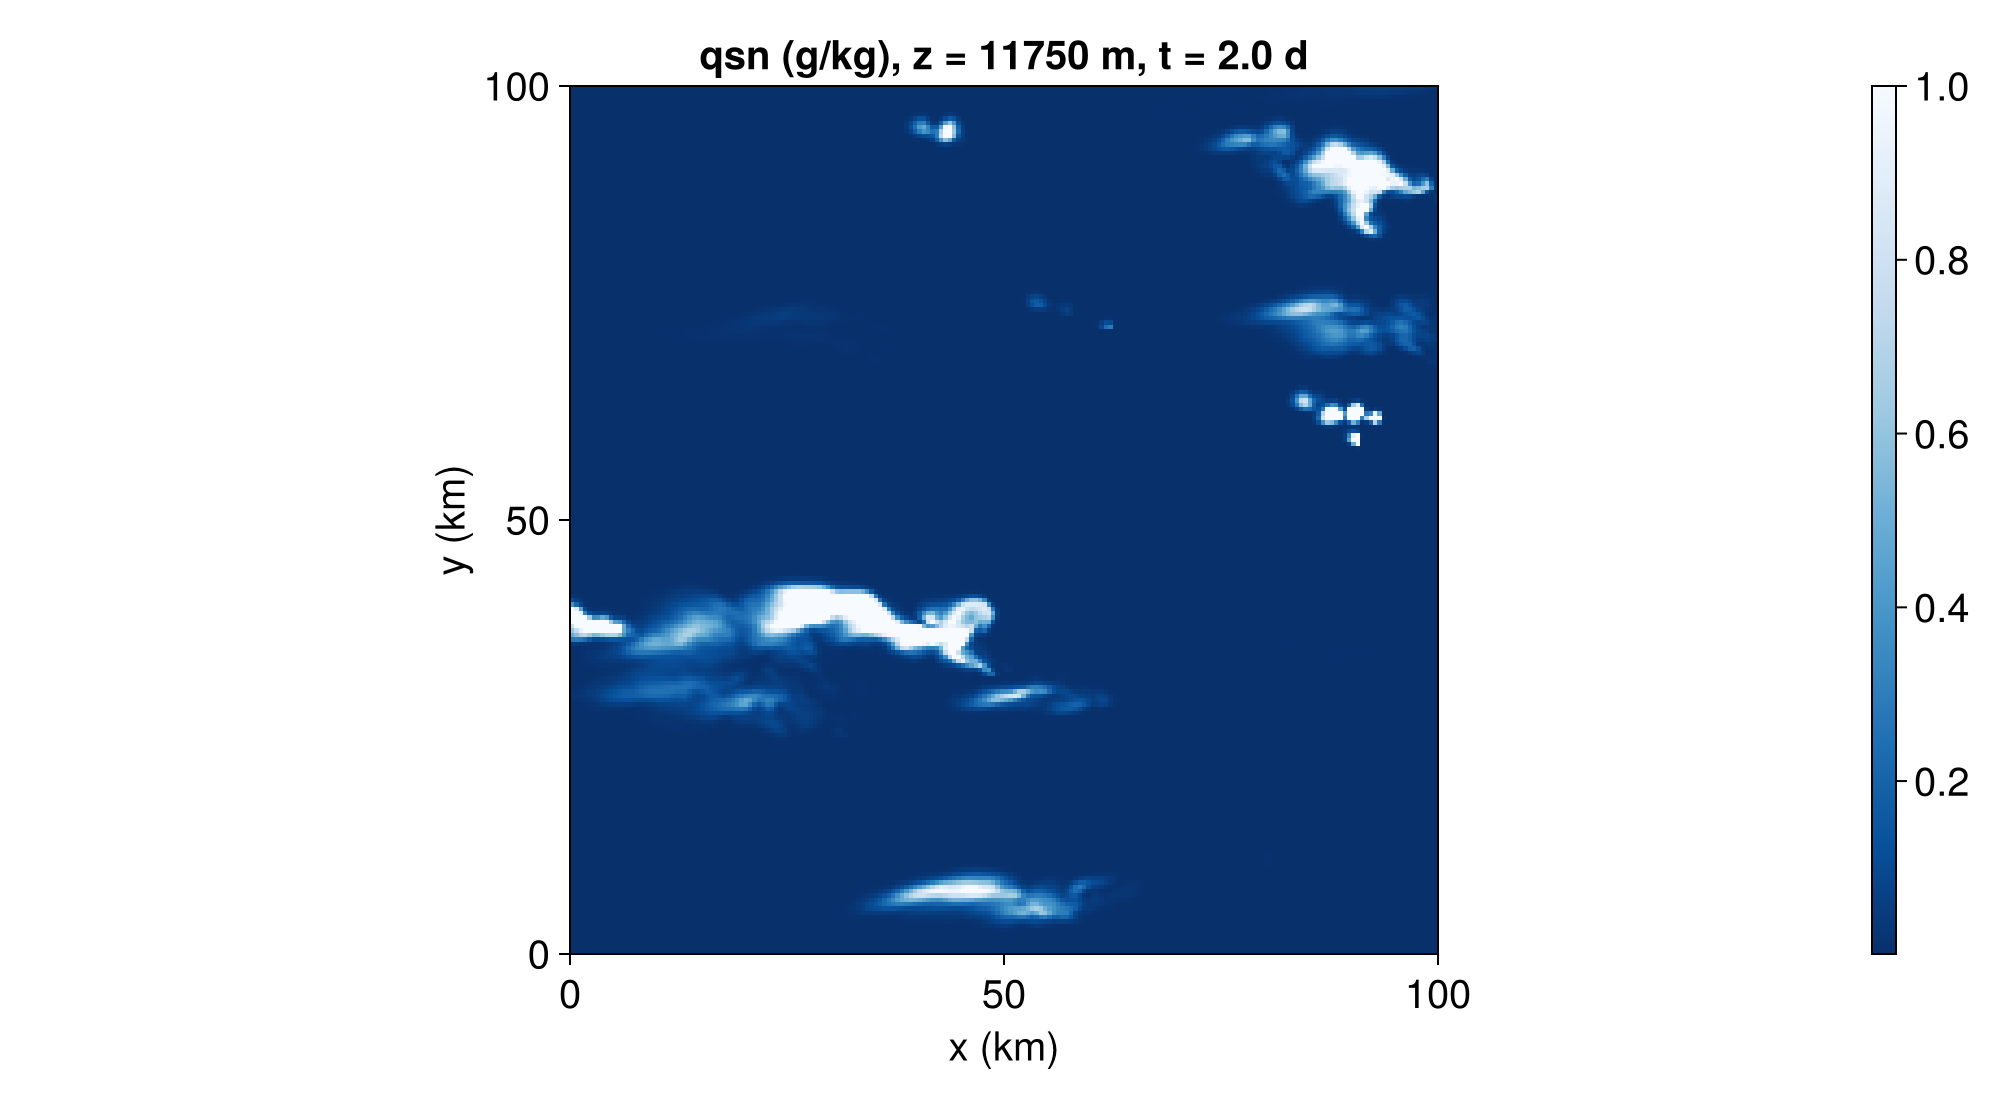

In [37]:
# log_10(x) = log10(max(x,1e-5))
fig_qcl = plot_xy(read_snapshot(rundir, "qci"; n = last); z = 12_000)   # a level of a 3D snapshot
fig_qcl = plot_xy(read_snapshot(rundir, "qsn"; n = last); z = 12_000)   # a level of a 3D snapshot
ax = plot_axes(fig_qcl)[1]
limits!(ax, 0, 100, 0, 100)
hm = ax.scene.plots[1]     # the heatmap in the first axis
hm.colorrange = (1e-3, 1)    # in the plotted units (log 10 g/kg here)
hm.colormap = Reverse(:Blues)
# hm.colorscale = log10
fig_qcl

In [11]:
# The latest state, from the newest checkpoint
ck = read_checkpoint(rundir)
keys(ck.fields)

(:ρu, :ρv, :ρw, :ρθ, :ρqᵛ, :ρqᶜˡ, :ρqᶜⁱ, :ρqʳ, :ρqˢⁿ, :ρe)

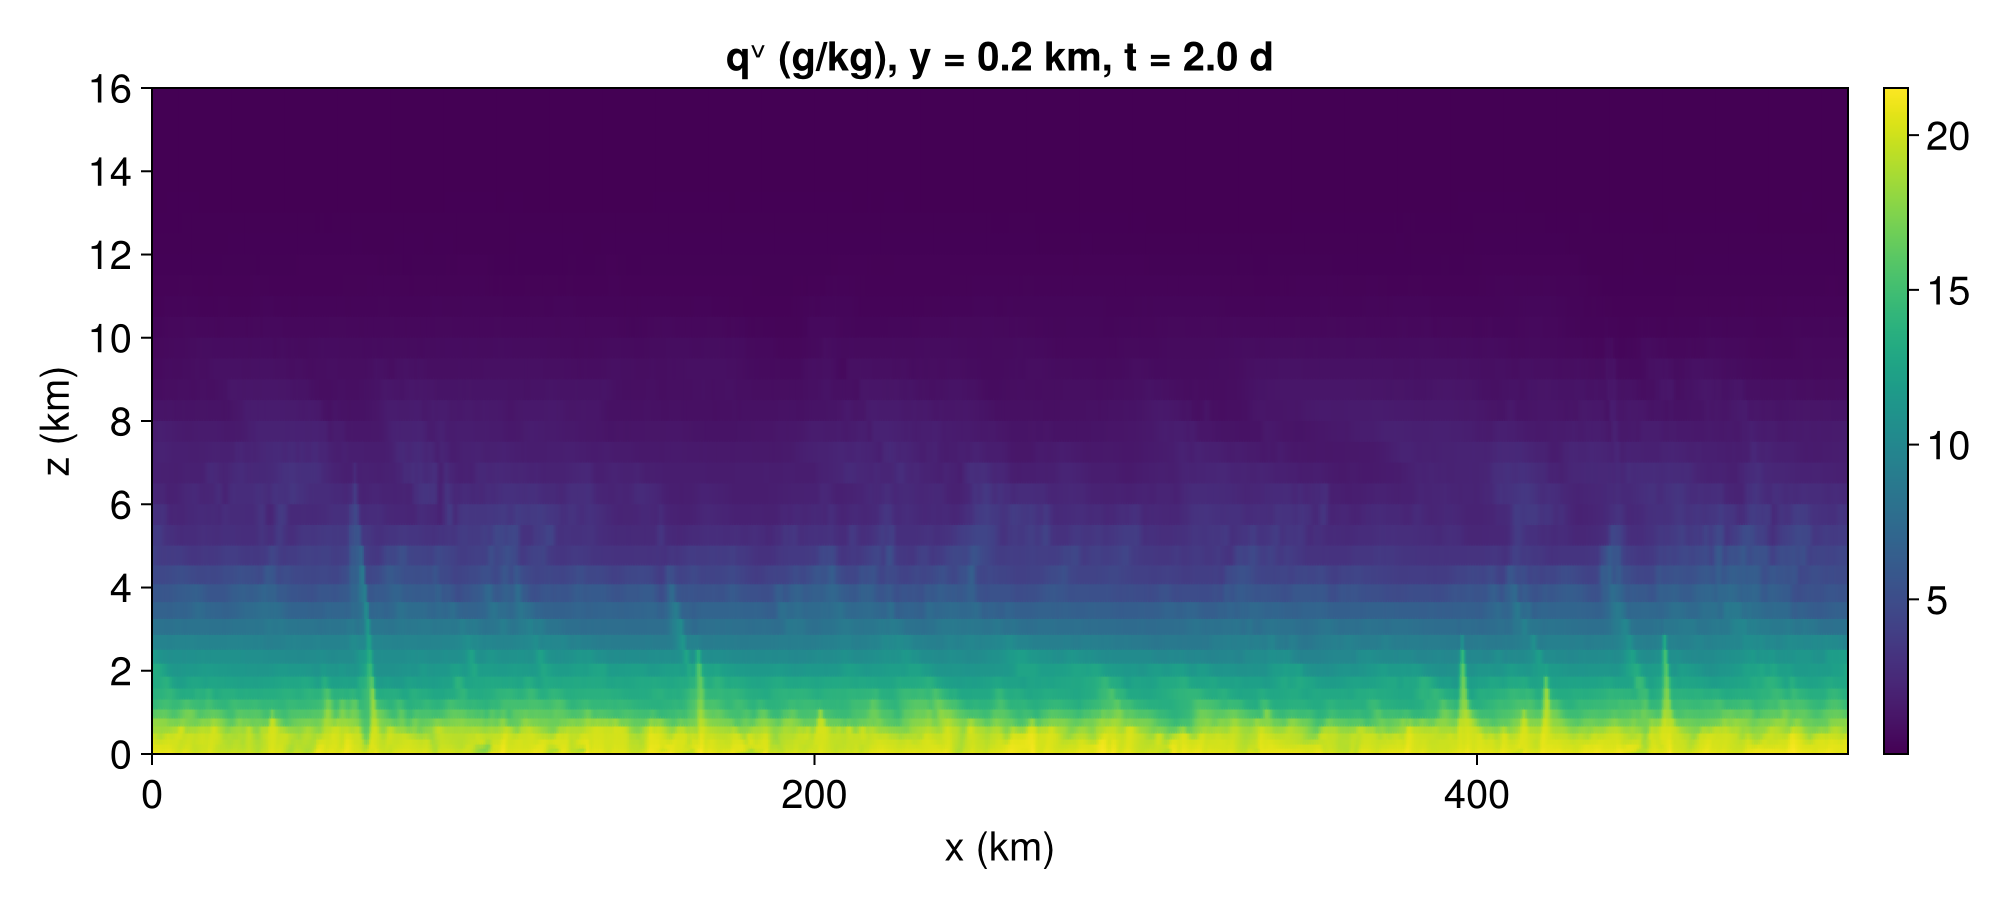

In [12]:
plot_xz(checkpoint_snapshot(ck, :ρqᵛ); j = 1)

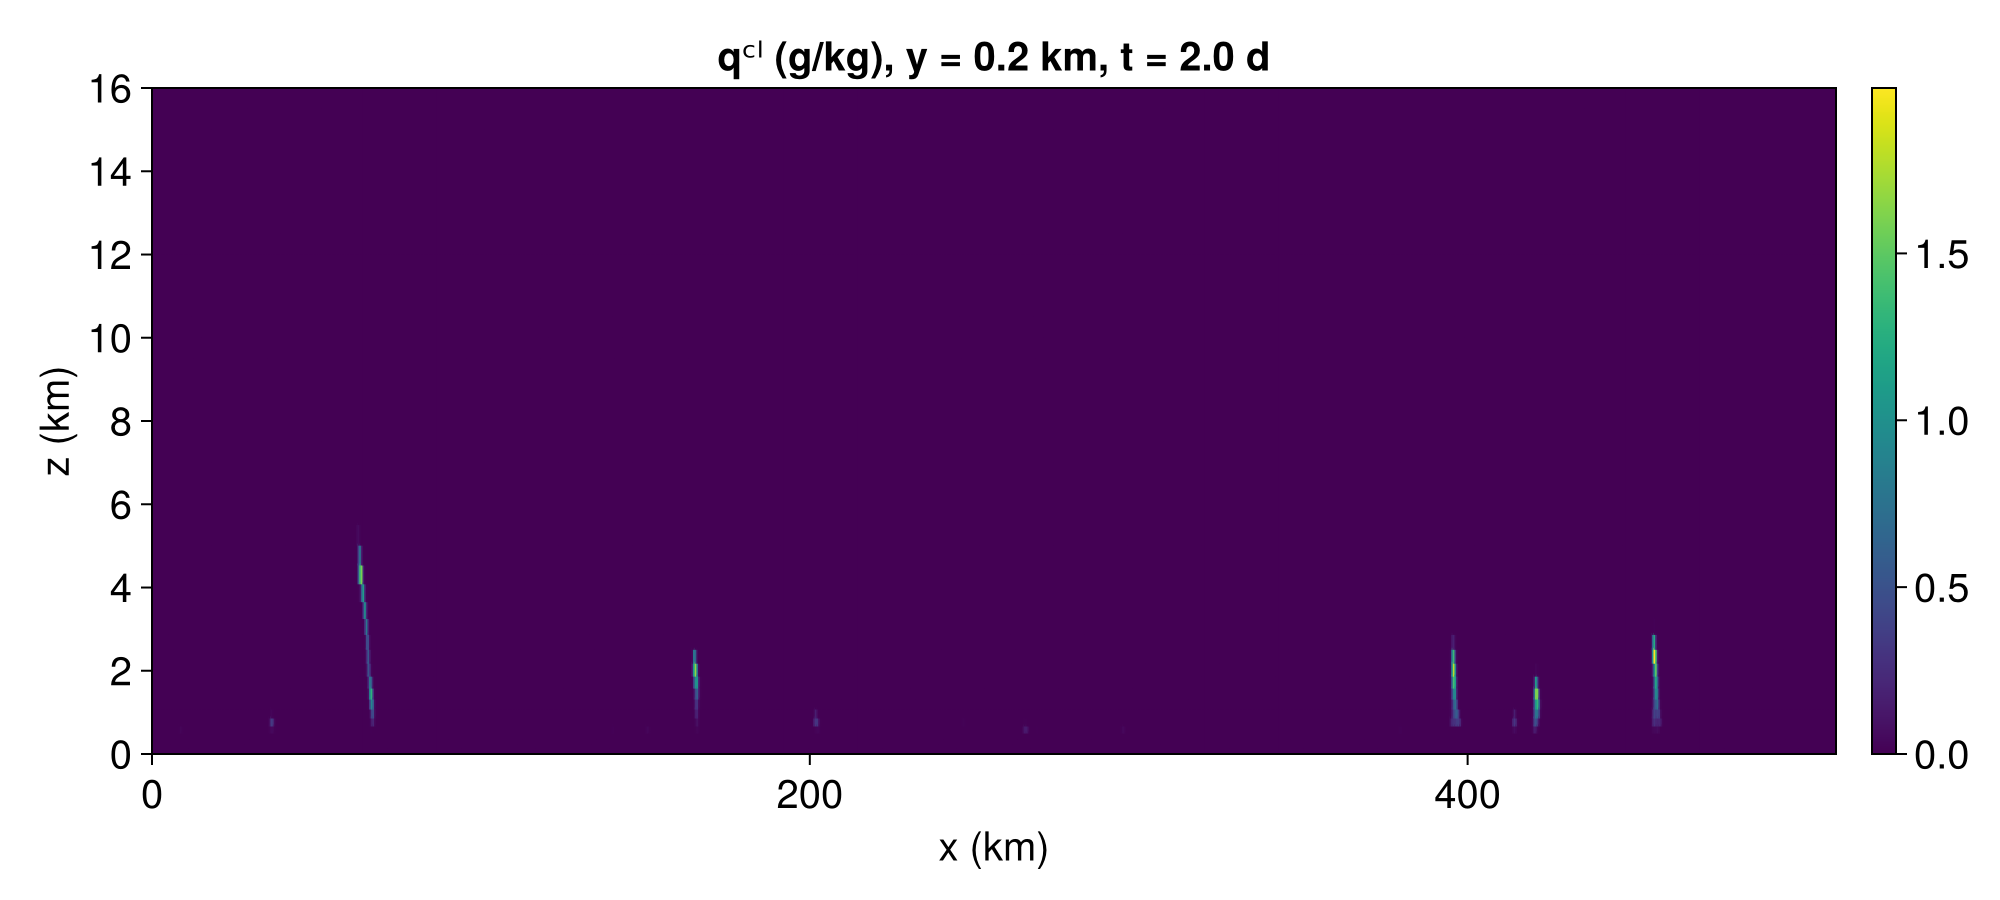

In [13]:
plot_xz(checkpoint_snapshot(ck, :ρqᶜˡ); j = 1)
